# 3. Does it make money? A walk-forward backtest

Design, following Gatev, Goetzmann and Rouwenhorst (2006):

* every six months, select 20 pairs using the **two previous years only**;
* trade them for six months with the rule of notebook 2, parameters frozen;
* 5 basis points of cost on every trade; returns measured on the capital committed to the 20 pairs.

Three ways to select pairs are compared:

| Selection | How pairs are chosen | Hedge ratio |
|---|---|---|
| **Cointegration** | most significant Engle-Granger tests, half-life between 3 and 60 days | regression, or Kalman filter |
| **Distance** | pairs whose normalised prices stayed closest (the original 2006 method) | one for one |
| **Random** | drawn at random within sectors: a placebo | regression |

These settings were fixed before looking at any result.

In [1]:
import sys
sys.path.insert(0, "..")  # make the `pairs` package importable from the notebooks folder

from dataclasses import replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pairs import (Rule, Settings, benjamini_hochberg, candidate_pairs, engle_granger, kalman_hedge, load_prices, metrics,
                   positions_from_zscore, run_backtest, scan_pairs, sector_of, simulate_pair, split_benchmark, trade_pair)
from pairs.plotting import use_style, BLUE, ORANGE, AQUA, YELLOW, MUTED, INK_SOFT, GRID

use_style()
pd.options.display.float_format = "{:.3f}".format

prices, benchmark = split_benchmark(load_prices("../data/prices.csv"))
log_prices = np.log(prices)
print(f"{prices.shape[1]} stocks, {len(prices):,} trading days, {prices.index[0]:%Y-%m-%d} to {prices.index[-1]:%Y-%m-%d}")

104 stocks, 4,243 trading days, 2010-01-04 to 2026-11-13


In [2]:
base = Settings()
cache = {}
strategies = {"Distance": dict(selection="distance"),
              "Cointegration": dict(selection="cointegration"),
              "Cointegration + Kalman": dict(selection="cointegration", method="kalman")}
results = {name: run_backtest(prices, replace(base, **options), cache) for name, options in strategies.items()}
placebo = [run_backtest(prices, replace(base, selection="random", seed=seed)) for seed in range(30)]
print(f"{results['Cointegration'].n_periods} six-month periods, from {results['Cointegration'].returns.index[0]:%Y-%m-%d} "
      f"to {results['Cointegration'].returns.index[-1]:%Y-%m-%d}")

30 six-month periods, from 2012-01-03 to 2026-11-13


## 3.1 Results

In [3]:
returns = pd.DataFrame({name: r.returns for name, r in results.items()})
table = metrics.summary(returns)
table["Profitable pairs"] = [(r.pairs["profit"] > 0).mean() for r in results.values()]
table["Trades per pair"] = [r.pairs["n_trades"].mean() for r in results.values()]
placebo_sharpe = np.array([metrics.sharpe_ratio(r.returns) for r in placebo])
table.loc["Random pairs (mean of 30 draws)"] = [np.mean([metrics.annualised_return(r.returns) for r in placebo]),
    np.mean([metrics.annualised_volatility(r.returns) for r in placebo]), placebo_sharpe.mean(), placebo_sharpe.std(ddof=1),
    np.mean([metrics.max_drawdown(r.returns) for r in placebo]), np.mean([(r.pairs["profit"] > 0).mean() for r in placebo]),
    np.mean([r.pairs["n_trades"].mean() for r in placebo])]
table.style.format({"Annual return": "{:.2%}", "Volatility": "{:.1%}", "Sharpe ratio": "{:.2f}", "Sharpe std error": "{:.2f}",
                    "Max drawdown": "{:.1%}", "Profitable pairs": "{:.0%}", "Trades per pair": "{:.1f}"})

,Annual return,Volatility,Sharpe ratio,Sharpe std error,Max drawdown,Profitable pairs,Trades per pair
Distance,1.33%,1.3%,0.99,0.32,-2.0%,45%,1.0
Cointegration,0.15%,2.7%,0.06,0.26,-9.5%,41%,1.1
Cointegration + Kalman,0.32%,2.0%,0.16,0.26,-6.5%,32%,0.8
Random pairs (mean of 30 draws),-0.69%,3.0%,-0.24,0.21,-16.3%,34%,0.9


Sharpe ratio of the 30 random draws: from -0.58 to 0.29


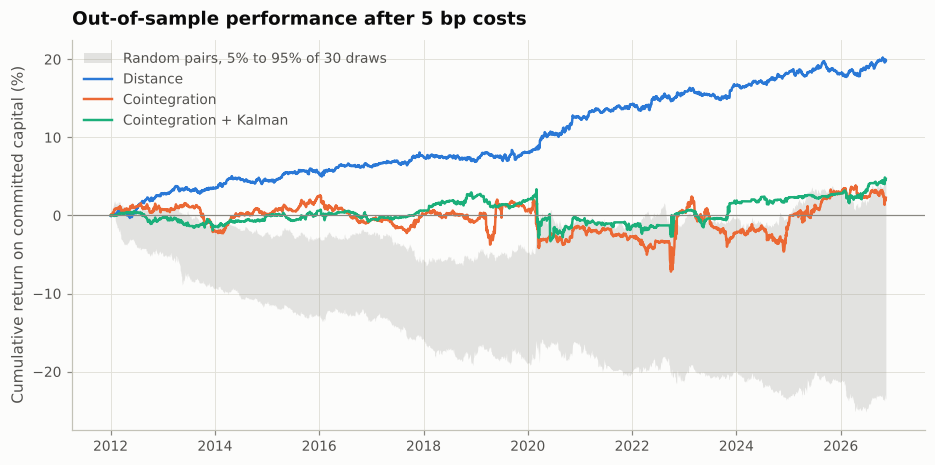

In [4]:
colors = {"Distance": BLUE, "Cointegration": ORANGE, "Cointegration + Kalman": AQUA}
placebo_paths = 100 * pd.DataFrame({i: r.returns for i, r in enumerate(placebo)}).cumsum()
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.fill_between(placebo_paths.index, placebo_paths.quantile(0.05, axis=1), placebo_paths.quantile(0.95, axis=1),
                color=MUTED, alpha=0.22, linewidth=0, label="Random pairs, 5% to 95% of 30 draws")
for name in returns.columns:
    ax.plot(returns.index, 100 * returns[name].cumsum(), color=colors[name], linewidth=1.6, label=name)
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.set_ylabel("Cumulative return on committed capital (%)"); ax.set_title("Out-of-sample performance after 5 bp costs")
ax.legend(loc="upper left");
print(f"Sharpe ratio of the 30 random draws: from {placebo_sharpe.min():.2f} to {placebo_sharpe.max():.2f}")

Reading the table:

* **Cointegration-selected pairs earn nothing.** A Sharpe ratio of 0.06 with a standard error of 0.26 is zero. The Kalman filter does not change that (0.16).
* **Random pairs lose money**, because the rule trades and pays costs without any edge. Their Sharpe ratio averages about -0.2. The cointegration strategies sit near the top of that placebo range, the distance strategy clearly above it.
* **Distance pairs earn 1.3% a year** with a Sharpe ratio near 1. This needs a closer look before it is believed.

Notebook 1 predicted the first point: pairs that pass the cointegration test are no more likely to stay cointegrated than other pairs.

## 3.2 Is the distance result robust?

A real effect should survive reasonable changes of the design. One choice is changed at a time:

,Distance,Cointegration,Cointegration + Kalman
Base case,0.99,0.06,0.16
Entry at 1.5 std,0.71,-0.05,0.15
Entry at 2.5 std,0.83,0.32,0.03
No stop-loss,0.69,0.10,0.13
10 pairs,0.74,0.03,0.41
40 pairs,0.69,-0.24,-0.02
1-year formation,-0.19,-0.35,-0.32
3-year formation,0.03,0.09,-0.02
3-month trading,0.55,0.01,0.13
No costs,1.12,0.13,0.24


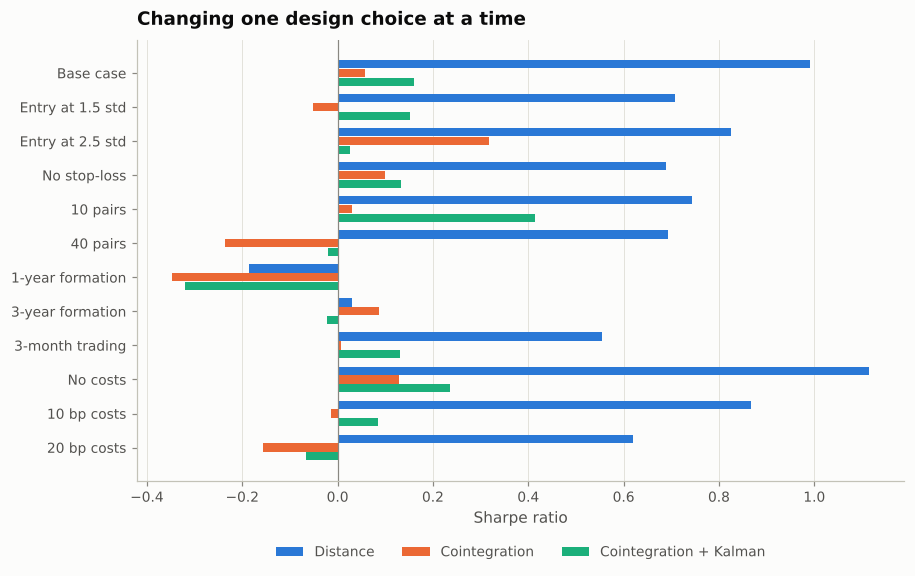

In [5]:
variants = {"Base case": {}, "Entry at 1.5 std": dict(rule=Rule(entry=1.5)), "Entry at 2.5 std": dict(rule=Rule(entry=2.5)),
            "No stop-loss": dict(rule=Rule(stop=50.0)), "10 pairs": dict(n_pairs=10), "40 pairs": dict(n_pairs=40),
            "1-year formation": dict(formation_days=252), "3-year formation": dict(formation_days=756),
            "3-month trading": dict(trading_days=63), "No costs": dict(cost_bps=0.0), "10 bp costs": dict(cost_bps=10.0),
            "20 bp costs": dict(cost_bps=20.0)}
rows = {label: {name: metrics.sharpe_ratio(run_backtest(prices, replace(base, **options, **change), cache).returns)
                for name, options in strategies.items()} for label, change in variants.items()}
robustness = pd.DataFrame(rows).T

fig, ax = plt.subplots(figsize=(9, 5.2))
y = np.arange(len(robustness))[::-1]
for offset, name in zip([0.26, 0.0, -0.26], robustness.columns):
    ax.barh(y + offset, robustness[name], height=0.24, color=colors[name], label=name)
ax.axvline(0, color=MUTED, linewidth=0.8); ax.set_yticks(y, robustness.index); ax.grid(axis="y", visible=False)
ax.set_xlabel("Sharpe ratio"); ax.set_title("Changing one design choice at a time")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3);
robustness.style.format("{:.2f}")

In [6]:
summary = pd.DataFrame({"Lowest": robustness.min(), "Median": robustness.median(), "Highest": robustness.max(),
                        "Variants with a positive Sharpe ratio": (robustness > 0).sum().astype(str) + f" of {len(robustness)}"})
summary

,Lowest,Median,Highest,Variants with a positive Sharpe ratio
Distance,-0.186,0.701,1.116,11 of 12
Cointegration,-0.348,0.018,0.317,7 of 12
Cointegration + Kalman,-0.321,0.107,0.413,8 of 12


The distance result does **not** pass this test cleanly:

* it holds when the entry level, the stop, the number of pairs or the costs change (Sharpe ratio between 0.6 and 1.1), and with three-month trading periods (0.55);
* it disappears when the formation window is one year (-0.19) or three years (0.03) instead of two.

The base case is the best of the windows tried. A strategy whose profit depends on the choice between one, two and three years of history, with no reason to prefer one, is not established. The cointegration strategies are near zero in every variant.

## 3.3 Where the distance profit comes from

Share of the total profit earned in 2012 and 2020: 37%
Years with a positive return: 13 of 15


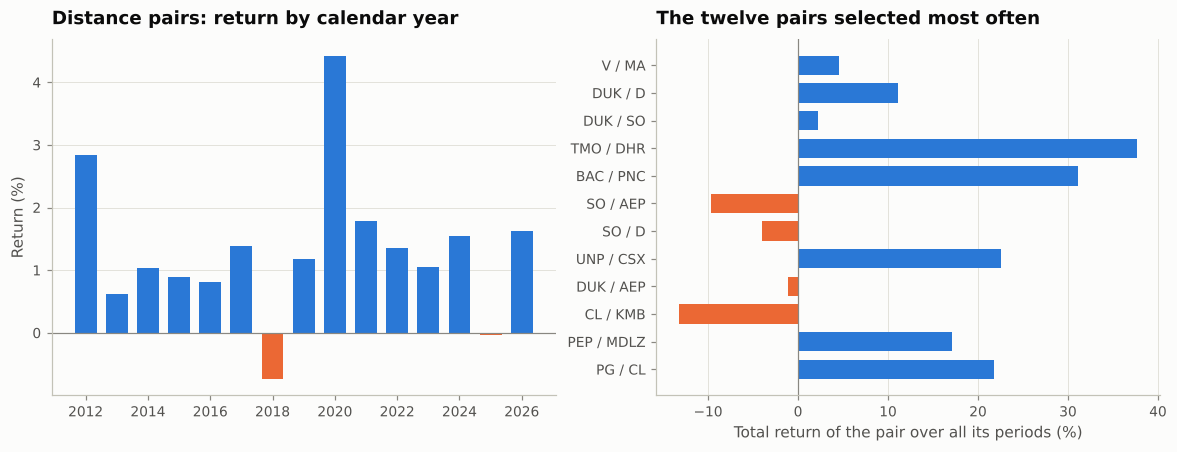

In [7]:
distance = results["Distance"]
yearly = pd.DataFrame({name: 100 * r.returns.groupby(r.returns.index.year).sum() for name, r in results.items()})
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.2))
left.bar(yearly.index, yearly["Distance"], color=[BLUE if v >= 0 else ORANGE for v in yearly["Distance"]], width=0.7)
left.axhline(0, color=MUTED, linewidth=0.8); left.grid(axis="x", visible=False)
left.set_ylabel("Return (%)"); left.set_title("Distance pairs: return by calendar year")
frequent = (distance.pairs.assign(pair=distance.pairs["y"] + " / " + distance.pairs["x"]).groupby("pair")
            .agg(periods=("profit", "size"), profit=("profit", "sum")).sort_values("periods", ascending=False).head(12))
right.barh(frequent.index[::-1], 100 * frequent["profit"][::-1], color=[BLUE if v >= 0 else ORANGE for v in frequent["profit"][::-1]], height=0.7)
right.axvline(0, color=MUTED, linewidth=0.8); right.grid(axis="y", visible=False)
right.set_xlabel("Total return of the pair over all its periods (%)"); right.set_title("The twelve pairs selected most often");
print(f"Share of the total profit earned in 2012 and 2020: {yearly['Distance'].loc[[2012, 2020]].sum() / yearly['Distance'].sum():.0%}")
print(f"Years with a positive return: {(yearly['Distance'] > 0).sum()} of {len(yearly)}")

The pairs the distance method picks are the ones anyone would name: two card networks, two railways, utilities, consumer-staples companies. Their spreads are tiny, so the strategy has a very low volatility (1.3% a year) and a correspondingly small return.

## 3.4 What 1.3% a year means

Returns are per unit of capital committed to the pairs, with no leverage. A 1.3% return with 1.3% volatility is only attractive with leverage, and leverage brings costs this backtest does not include: financing, the fee for borrowing shares to sell short, and the price impact of trading.

In [8]:
costs = pd.DataFrame({cost: {name: metrics.annualised_return(run_backtest(prices, replace(base, **options, cost_bps=float(cost)), cache).returns)
                             for name, options in strategies.items()} for cost in [0, 5, 10, 20, 30]}).T
costs.index.name = "Cost (bp)"
costs.style.format("{:.2%}")

,Distance,Cointegration,Cointegration + Kalman
Cost (bp),,,
0,1.50%,0.34%,0.47%
5,1.33%,0.15%,0.32%
10,1.17%,-0.04%,0.17%
20,0.83%,-0.42%,-0.13%
30,0.50%,-0.80%,-0.43%


## Summary

**Cointegration-based pairs trading did not work on this universe.** Over fifteen years and 30 six-month periods, pairs selected by an Engle-Granger test earned 0.2% a year after costs, statistically zero, with or without a Kalman filter. The reason is upstream of the trading rule: the test selects pairs that look cointegrated by chance, and they do not stay so (notebook 1).

**The simpler distance method did better, but not robustly.** Its Sharpe ratio is near 1 in the base case and positive in most variants, yet it vanishes when the formation window changes from two years to one or three. Having tried three selection methods and a dozen variants, one good cell is what chance would produce. The honest reading is "possibly a small effect, not established".

**Why this is the expected outcome.** Pairs trading on large US stocks was profitable in the 1960s to 1980s and has declined steadily since, as documented by Do and Faff (2010). The stocks here are among the most heavily traded in the world, and the strategy has been public for decades.

**Limits of this study.** Daily closing prices only; a universe of today's large companies (survivorship bias, which matters less for a market-neutral strategy than for a long-only one, but removes the pairs that broke because one company failed); no borrowing costs; one market.